**Dataset Credits:** Ahsan Raza (https://www.kaggle.com/datasets/ahsan81/hotel-reservations-classification-dataset)

- `booking_id:` unique identifier of each booking
- `no_of_adults:` Number of adults
- `no_of_children:` Number of Children
- `no_of_weekend_nights:` Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel
- `no_of_week_nights:` Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel
- `type_of_meal_plan:` Type of meal plan booked by the customer
- `required_car_parking_space:` Does the customer require a car parking space? (0 - No, 1- Yes)
- `room_type_reserved:` Type of room reserved by the customer. The values are ciphered (encoded) by INN Hotels
- `lead_time:` Number of days between the date of booking and the arrival date
- `arrival_year:` Year of arrival date
- `arrival_month:` Month of arrival date
- `arrival_date:` Date of the month
- `market_segment_type:` Market segment designation
- `repeated_guest:` Is the customer a repeated guest? (0 - No, 1- Yes)
- `no_of_previous_cancellations:` Number of previous bookings that were canceled by the customer prior to the current booking
- `no_of_previous_bookings_not_canceled:` Number of previous bookings not canceled by the customer prior to the current booking
- `avg_price_per_room:` Average price per day of the reservation; prices of the rooms are dynamic (in euros)
- `no_of_special_requests:` Total number of special requests made by the customer (e.g. high floor, view from the room, etc)
- `booking_status:` Flag indicating if the booking was canceled or not (Not_Canceled = 0, Canceled = 1)




**Import Necessary Libraries**


In [2]:
# Import Necessary Libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,RandomizedSearchCV,GridSearchCV,KFold,StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC



### Task 1: Data Preprocessing and EDA

1. Import the data from the `"hotel_reservations.csv"` file and store it in a variable df.
2. Display the number of rows and columns in the dataset.
3. Display the first few rows of the dataset to get an overview.
5. Remove the columns `booking_id, arrival_year, arrival_month, and arrival_date` as they do not add significant value to the predictive model.
6. Visualize the booking_status using a count plot.
7. Visualize the lead time for canceled and not canceled bookings using a box plot.
8. Visualize the average price per room for canceled and not canceled bookings using a box plot.
9. Encode categorical variables: type_of_meal_plan, room_type_reserved, and market_segment_type using one-hot encoding.

In [5]:
# Import the data from the "hotel_reservations.csv" file and store it in a variable df.

df=pd.read_csv("hotel_reservations.csv")

# Display the number of rows and columns in the dataset

print(f"ROWS={df.shape[0]} COLUMNS={df.shape[1]}")

# Display the first few rows of the dataset to get an overview
df.head()

ROWS=36275 COLUMNS=19


,booking_id,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [8]:
# Remove the columns booking_id, arrival_year, arrival_month, and arrival_date
df=df.drop(columns=["booking_id","arrival_year","arrival_month","arrival_date"])

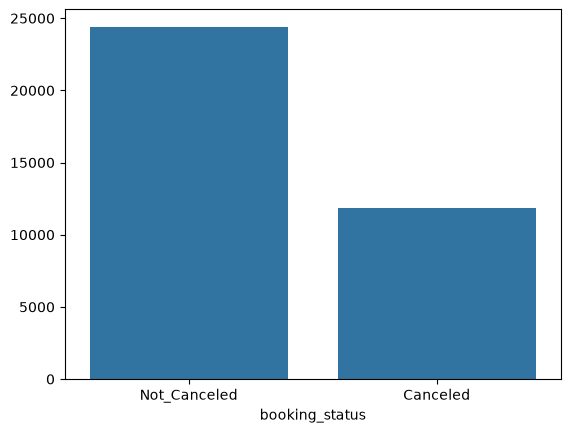

In [ ]:
# Visualize the booking_status
sns.barplot(x=df["booking_status"].value_counts().index,y=df["booking_status"].value_counts().values)

plt.show()


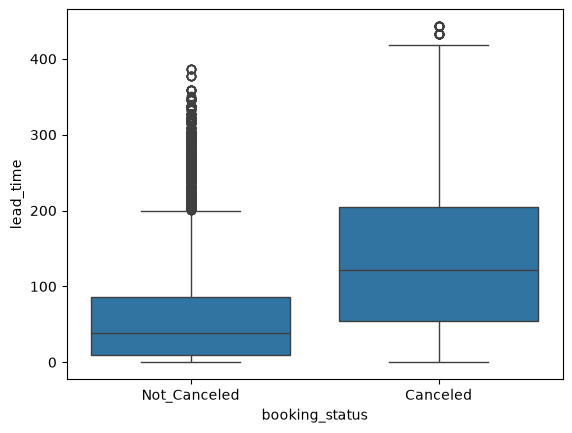

In [30]:
# Visualize the lead time for canceled and not canceled bookings using a box plot


sns.boxplot(df,x="booking_status",y="lead_time")
plt.show()

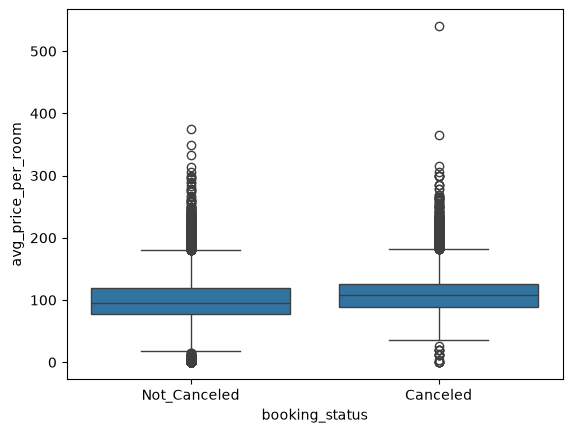

In [31]:
# Visualize the average price per room for canceled and not canceled bookings sns.boxplot(x='booking_status', y='avg_price_per_room', data=df)


sns.boxplot(df,x="booking_status",y="avg_price_per_room")
plt.show()

In [33]:
# Encode categorical variables : type_of_meal_plan, room_type_reserved, and market_segment_type using one-hot encoding.

df=pd.get_dummies(df,columns=["type_of_meal_plan","room_type_reserved","market_segment_type"],drop_first=True)

In [34]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status,type_of_meal_plan_Meal Plan 2,type_of_meal_plan_Meal Plan 3,type_of_meal_plan_Not Selected,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
0,2,0,1,2,0,224,0,0,0,65.00,0,Not_Canceled,False,False,False,False,False,False,False,False,False,False,False,True,False
1,2,0,2,3,0,5,0,0,0,106.68,1,Not_Canceled,False,False,True,False,False,False,False,False,False,False,False,False,True
2,1,0,2,1,0,1,0,0,0,60.00,0,Canceled,False,False,False,False,False,False,False,False,False,False,False,False,True
3,2,0,0,2,0,211,0,0,0,100.00,0,Canceled,False,False,False,False,False,False,False,False,False,False,False,False,True
4,2,0,1,1,0,48,0,0,0,94.50,0,Canceled,False,False,True,False,False,False,False,False,False,False,False,False,True


### Task 2: Feature Scaling

1. Standardize the numerical features `lead_time` and `avg_price_per_room`.
2. Define features (X) and target (y).

In [40]:
# Standardize the numerical features

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df[["lead_time","avg_price_per_room"]]=scaler.fit_transform(df[["lead_time","avg_price_per_room"]])

# Define features(X) and target (y: booking_status)

X=df.drop(columns=["booking_status"])
y=df["booking_status"]

### Task 3: Implementing K-Fold Cross Validation

1. Initialize a KFold cross-validator with 7 splits.
2. Perform k-fold cross-validation using Naive Bayes and calculate the average accuracy.
3. Perform k-fold cross-validation using a Logistic Regression and calculate the average accuracy.
4. Perform k-fold cross-validation using a decision tree classifier and calculate the average accuracy.

In [48]:
from sklearn.model_selection import cross_val_score,cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings("ignore")

In [54]:

# Initialize KFold with 7 splits.

kf=KFold(n_splits=7,shuffle=True,random_state=42)

# Cross validation with Naive Bayes

nb_cv_scores=cross_val_score(GaussianNB(),X,y,cv=kf,scoring="accuracy")
print("Naive Bayes Cross-Validation Accuracy: ", nb_cv_scores.mean())


# Cross validation with Logistic Regression

lr_cv_scores=cross_val_score(LogisticRegression(),X,y,cv=kf,scoring="accuracy")
print("Logistic Regression Cross-Validataion Accuracy: ", lr_cv_scores.mean())


# Cross validation with Decision Tree
dt_model = DecisionTreeClassifier()
dt_cv_score = cross_val_score(dt_model, X, y, cv=kf, scoring="accuracy")
print("Decision Tree Cross-Validation Accuracy: ", dt_cv_score.mean())

Naive Bayes Cross-Validation Accuracy:  0.4086008945293444
Logistic Regression Cross-Validataion Accuracy:  0.8004685935356991
Decision Tree Cross-Validation Accuracy:  0.8569539929818571


### Task 4: Implementing Stratified K-Fold Cross Validation

1. Initialize a StratifiedKFold cross-validator with 7 splits
2. Perform stratified k-fold cross-validation using Naive Bayes and calculate the average accuracy.
3. Perform stratified k-fold cross-validation using a Logistic Regression and calculate the average accuracy.
4. Perform stratified k-fold cross-validation using a Decision Tree classifier and calculate the average accuracy.

In [ ]:
# Initialize a StratifiedKFold cross-validator with 7 splits
skf=StratifiedKFold(n_splits=7,shuffle=True,random_state=42)


# Perform stratified k-fold cross-validation using Naive Bayes
nb_cv_scores=cross_val_score(GaussianNB(),X,y,cv=skf,scoring="accuracy")
print("Naive Bayes Stratified-Cross-Validation Accuracy: ", nb_cv_scores.mean())

# Perform stratified k-fold cross-validation using a Logistic Regression

lr_cv_scores=cross_val_score(LogisticRegression(),X,y,cv=skf,scoring="accuracy")
print("Logistic Regression Stratified-Cross-Validataion Accuracy: ", lr_cv_scores.mean())

# Perform stratified k-fold cross-validation using a Decision Tree classifier

dt_model = DecisionTreeClassifier()
dt_cv_score = cross_val_score(dt_model, X, y, cv=skf, scoring="accuracy")
print("Decision Tree Stratified-Cross-Validation Accuracy: ", dt_cv_score.mean())



Naive Bayes Stratified-Cross-Validation Accuracy:  0.40862851035462067
Logistic Regression Stratified-Cross-Validataion Accuracy:  0.7996416346692049
Decision Tree Stratified-Cross-Validation Accuracy:  0.8584147701433059


### Task 5: Implementing Grid Search CV

1. Initialize GridSearchCV with Naive Bayes and Random Forest:
    - Naive Bayes: var_smoothing [1e-9, 1e-8, 1e-7]
    - Random Forest: n_estimators [10, 50, 100], max_depth [5, 10, 15]
<br></br>
2. Fit GridSearchCV with Naive Bayes and Random Forest, and find the best parameters.
3. Print the best parameters for each model.

In [56]:
from sklearn.ensemble import RandomForestClassifier

In [60]:
clf=GridSearchCV(DecisionTreeClassifier(),param_grid={"max_depth":[5,10,15]})
clf_model=clf.fit(X,y)
pd.DataFrame(clf_model.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.132016,0.020328,0.028197,0.006053,5,{'max_depth': 5},0.834735,0.832116,0.822605,0.828532,0.822605,0.828119,0.004914,3
1,0.165362,0.024906,0.027823,0.003439,10,{'max_depth': 10},0.869194,0.869331,0.864232,0.868918,0.858856,0.866106,0.004097,2
2,0.198630,0.043300,0.029732,0.007291,15,{'max_depth': 15},0.866713,0.871813,0.864232,0.870434,0.863267,0.867292,0.003353,1


In [ ]:
# Initialize GridSearchCV with Naive Bayes and Random Forest 
model_params={
    "Naive_Bayes":{
        "model":GaussianNB(),
        "params": {'var_smoothing': [1e-9, 1e-8, 1e-7]}},
    "Random_Forest":{
        "model":RandomForestClassifier(),
        "params":{"n_estimators": [10, 50, 100],"max_depth":[5,10,15]}
    }
}



# Fit GridSearchCV with Naive Bayes and Random Forest, and find the best parameters.
scores=[]
for key,val in model_params.items():
    clf=GridSearchCV(val["model"],val["params"],cv=7,return_train_score=False)
    clf.fit(X, y)
    scores.append({"model":key,"best_score":clf.best_score_,"best_params":clf.best_params_})







In [64]:
# Print the best parameters for each model.
df_scores = pd.DataFrame(scores, columns=["model", "best_score", "best_params"])
df_scores

,model,best_score,best_params
0,Naive_Bayes,0.409483,{'var_smoothing': 1e-07}
1,Random_Forest,0.877050,"{'max_depth': 15, 'n_estimators': 100}"


### Task 6: Implementing Randomized Search CV

1. Initialize RandomizedSearchCV for RandomForest with the given parameters:
   - Random Forest: n_estimators [10, 50, 100], max_depth [5, 10, 15, 20]
<br></br>
2. Fit RandomizedSearchCV with RandomForest model and find the best parameters.
2. Print the best parameters.

In [67]:
# Initialize RandomizedSearchCV and fit with RandomForest model
clf=RandomizedSearchCV(RandomForestClassifier(),{"n_estimators":[5,50,100],"max_depth":[5,10,15,20]},cv=7,return_train_score=False,n_iter=3)
clf.fit(X,y)
# Print Best Parameters

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [5, 10, ...], 'n_estimators': [5, 50, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",3
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",7
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``re

In [68]:
print("Best Parameters for Random Forest (RandomizedSearchCV): ", clf.best_params_)
df = pd.DataFrame(clf.cv_results_)
df

Best Parameters for Random Forest (RandomizedSearchCV):  {'n_estimators': 100, 'max_depth': 15}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_estimators,param_max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,mean_test_score,std_test_score,rank_test_score
0,1.399600,0.200882,0.075434,0.011297,50,15,"{'n_estimators': 50, 'max_depth': 15}",0.879028,0.882671,0.873601,0.874566,0.876882,0.869162,0.872250,0.875451,0.004157,2
1,2.625167,0.147276,0.124208,0.008601,100,15,"{'n_estimators': 100, 'max_depth': 15}",0.877098,0.881899,0.877653,0.878039,0.878618,0.869741,0.875724,0.876968,0.003432,1
2,2.036439,0.434697,0.109813,0.046907,100,10,"{'n_estimators': 100, 'max_depth': 10}",0.864171,0.863180,0.853917,0.855847,0.855847,0.848707,0.847935,0.855658,0.005857,3
